# Space-Partitioning Local Bayesian Optimisation — Guided Single-Function Walkthrough

This read-only notebook walks step by step through an opt-in **Space-Partitioning Local BO** pipeline (`bayesian_bbo.space_partitioning`), adapted for **maximisation** from JetBrains Research's NeurIPS 2020 BBO Challenge method (**SPBOpt / Space-Decay**, [arXiv:2012.10335](https://arxiv.org/abs/2012.10335)).

### Why use space partitioning instead of a single global GP?
A single global Gaussian Process assumes the objective behaves with the same smoothness and noise everywhere in $[0, 1]^d$. When a function has:
- an isolated outlier spike (like F1),
- a narrow local ridge smoothed over by global fits (like F2), or
- sharp corner / multi-modal structure in higher dimensions (F4–F8),

focusing a **local GP** inside a learned promising sub-region + **trust-region box** can model local curvature much more sharply.

### The 5 steps we will walk through
1. **Select one function & load data** through `CURRENT_WEEK`.
2. **Partition the search space (`K-Means + SVM`)** to separate higher-output points from lower-output points.
3. **Rank-transform local outputs & fit a local GP** on the promising leaf only.
4. **Build an ARD-shaped trust region**, sample **Sobol** candidates inside it, and filter them through the **SVM boundary**.
5. **Select a candidate** (Thompson sampling or local EI) and compare it apples-to-apples against your global `sobol_lbfgs` GP.

> **Read-only experiment:** Nothing is written to `data/` or exported from this notebook.

## Step 1. Choose one function & settings

Change **`FUNCTION_ID`** (`1` through `8`) below to explore any function. All other knobs are exposed right here so you can test how each stage responds:

- `MIN_REGION_POINTS`: minimum observations required in each child cluster to allow a K-Means + SVM split (prevents starving the local GP on small datasets).
- `MAX_DEPTH`: maximum number of recursive splits.
- `TRUST_LENGTH`: base side length of the trust-region box around the active region's best observed point (`0 < TRUST_LENGTH <= 1`).
- `USE_RANK_TRANSFORM`: monotonically maps local `y` values to standard-normal quantiles so extreme scales or outliers cannot distort the local GP.
- `ACQUISITION`: `'thompson'` (draws one random curve from the local GP posterior, like SPBOpt/TuRBO) or `'ei'` (deterministic local Expected Improvement).

In [11]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.data import load_observations
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.space_partitioning import (
    SpacePartitioningConfig,
    SpacePartitioningOptimizer,
    rank_gaussian_transform,
)
from bayesian_bbo.submission import format_submission
from bayesian_bbo.visualisation import plot_gp_2d, plot_gp_slices

# --- Single-function controls ---
CURRENT_WEEK = 6
FUNCTION_ID = 3            # Pick any function 1..8
MIN_REGION_POINTS = 4      # Minimum points per cluster (4 lets 16-point F2 split 12 vs 4; raise for larger functions)
MAX_DEPTH = 3
TRUST_LENGTH = 0.40
LOCAL_CANDIDATES = 2048
USE_RANK_TRANSFORM = True
ACQUISITION = 'thompson'   # 'thompson' or 'ei'
LOCAL_XI = 0.0             # Used only when ACQUISITION == 'ei'
SVM_KERNEL = 'rbf'         # 'rbf', 'linear', or 'poly'

# Reference global policy (matching Notebook 06) for side-by-side comparison only
GLOBAL_KERNEL_MAP = {
    1: 'Rational Quadratic', 2: 'RBF', 3: 'Rational Quadratic', 4: 'Matérn 3/2',
    5: 'Rational Quadratic', 6: 'Rational Quadratic', 7: 'Matérn 3/2', 8: 'Rational Quadratic',
}
GLOBAL_ALPHA_MAP = {1: 0.1, 2: 0.1, 3: 0.1, 4: 0.1, 5: 0.1, 6: 0.0, 7: 0.0, 8: 0.0}

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory.')
data_root = matches[0]

observations = load_observations(data_root, FUNCTION_ID, up_to_week=CURRENT_WEEK)
summary = pd.Series({
    'function_id': FUNCTION_ID,
    'dimension': observations.dimension,
    'observations_through_week': CURRENT_WEEK,
    'n_points': len(observations.outputs),
    'min_y': float(np.min(observations.outputs)),
    'median_y': float(np.median(observations.outputs)),
    'best_y': observations.best_output,
    'std_y': float(np.std(observations.outputs)),
    'best_input': format_submission(observations.best_input),
})
display(summary.to_frame(name='value'))

,value
function_id,3
dimension,3
observations_through_week,6
n_points,21
min_y,-0.398926
median_y,-0.09419
best_y,-0.005895
std_y,0.078873
best_input,0.194638-0.363906-0.466721


## Step 2. Partition the search space (`K-Means` + `SVM`) & fit the local GP

Here is what `SpacePartitioningOptimizer.suggest(observations)` does under the hood:

1. **Standardise `[x, y]`** (using rank-transformed `y` if `USE_RANK_TRANSFORM=True`) so neither input ranges nor wild output scales dominate clustering.
2. **Cluster into 2 groups with `K-Means`:** The cluster with the **higher average observed output** is labelled *good*; the other is *bad*.
3. **Check the stopping rule:** If splitting would leave fewer than `MIN_REGION_POINTS` in either cluster (or `MAX_DEPTH` is reached), stop — otherwise fit an **SVM classifier** on `x` to draw the nonlinear boundary separating good vs. bad space, and keep only the good cluster for the next split.
4. **Fit the local GP:** Train an ARD Matérn 3/2 GP *only* on the surviving observations in the promising leaf.

Notice the output table below: check how many splits occurred, how much higher the *good* cluster's mean output is than the *bad* cluster's, and which observations survived into the local GP.

In [12]:
sp_config = SpacePartitioningConfig(
    min_region_points=MIN_REGION_POINTS,
    max_depth=MAX_DEPTH,
    trust_length=TRUST_LENGTH,
    candidates=LOCAL_CANDIDATES,
    acquisition=ACQUISITION,
    xi=LOCAL_XI,
    use_rank_transform=USE_RANK_TRANSFORM,
    svm_kernel=SVM_KERNEL,
    length_cap=CONFIG['length_caps'][FUNCTION_ID],
    seed=CONFIG['random_state'],
)
sp_result = SpacePartitioningOptimizer(sp_config).suggest(observations)
partition = sp_result.partition

if partition.splits:
    split_df = pd.DataFrame([
        {
            'depth': s.depth,
            'good_count': s.good_count,
            'bad_count': s.bad_count,
            'good_mean_y': s.good_mean,
            'bad_mean_y': s.bad_mean,
            'mean_gap': s.good_mean - s.bad_mean,
        }
        for s in partition.splits
    ])
    print(f'Completed {len(partition.splits)} K-Means + SVM split(s); {len(partition.active_indices)}/{len(observations.outputs)} points kept in the promising leaf:')
    display(split_df.round(6))
else:
    print(
        f'No split performed (all {len(observations.outputs)} points kept). '
        f'Either fewer than 2 * MIN_REGION_POINTS ({2 * MIN_REGION_POINTS}) points exist or K-Means produced a cluster smaller than MIN_REGION_POINTS.'
    )

active_mask = np.zeros(len(observations.outputs), dtype=bool)
active_mask[partition.active_indices] = True
obs_table = pd.DataFrame({
    'obs_idx': np.arange(len(observations.outputs)),
    'week': observations.weeks,
    'in_active_leaf': active_mask,
    'raw_y': observations.outputs,
    'rank_gaussian_y': rank_gaussian_transform(observations.outputs),
    'coords': [format_submission(x) for x in observations.inputs],
}).sort_values('raw_y', ascending=False)
print('Top observations (showing which points feed the local GP):')
display(obs_table.head(10).round(6))

Completed 1 K-Means + SVM split(s); 10/21 points kept in the promising leaf:


,depth,good_count,bad_count,good_mean_y,bad_mean_y,mean_gap
0,0,10,11,-0.058799,-0.122541,0.063741


Top observations (showing which points feed the local GP):


,obs_idx,week,in_active_leaf,raw_y,rank_gaussian_y,coords
15,15,1,True,-0.005895,1.980752,0.194638-0.363906-0.466721
20,20,6,True,-0.011536,1.465234,0.392553-0.473772-0.496042
3,3,0,True,-0.034835,1.179761,0.492581-0.611593-0.340176
13,13,0,True,-0.036378,0.967422,0.600097-0.725136-0.066089
16,16,2,False,-0.038005,0.791639,0.292059-0.194387-0.490197
18,18,4,True,-0.043851,0.637484,0.261123-0.854114-0.486273
10,10,0,False,-0.046947,0.497201,0.220549-0.297825-0.343555
4,4,0,False,-0.048008,0.366106,0.134622-0.219917-0.458206
14,14,0,True,-0.056758,0.241040,0.965995-0.861120-0.566829
1,1,0,True,-0.087963,0.119648,0.242114-0.644074-0.272433


## Step 3. Inspect the local GP & ARD-shaped trust-region box

After fitting the local GP on the active leaf:
- **Target units:** When `USE_RANK_TRANSFORM=True`, the local GP predicts in **rank-Gaussian units** (monotone z-scores around `0`), *not* raw objective units. This prevents outliers from inflating local variance, but means you should never compare `local_mean` directly against `best_y` in raw units.
- **Trust region:** Centered on the active region's best observed point (`center`), with side lengths proportional to `TRUST_LENGTH` and scaled by the local GP's fitted ARD length scales (longer length scale → wider step allowed; shorter length scale → tighter focus).
- **SVM filtering:** Sobol points are drawn inside the trust region, snapped to 6 decimals, deduplicated against past observations, and filtered to keep only points inside the learned SVM good region (falling back to the full trust-region pool if 0 Sobol points pass).

In [13]:
print('Fitted local GP kernel:')
print(' ', sp_result.local_gp.kernel_)
print(
    f'Target space: {sp_result.target_space} | '
    f'local_mean={sp_result.local_mean:.4f}, local_std={sp_result.local_std:.4f}, '
    f'local_score ({ACQUISITION})={sp_result.local_score:.4f}'
)
print(
    f'Sobol trust-region pool: {sp_result.candidate_pool_in_region}/{sp_result.candidate_pool_total} '
    f'unused points passed the SVM good-region filter (filter active: {sp_result.used_region_filter})'
)

best_local_x = observations.inputs[partition.active_indices][
    int(np.argmax(observations.outputs[partition.active_indices]))
]
tr_table = pd.DataFrame({
    'dim': [f'x{i + 1}' for i in range(observations.dimension)],
    'leaf_best': best_local_x,
    'trust_lower': sp_result.trust_lower,
    'trust_upper': sp_result.trust_upper,
    'box_width': sp_result.trust_upper - sp_result.trust_lower,
    'sp_candidate': sp_result.candidate,
    'delta_from_best': sp_result.candidate - best_local_x,
})
display(tr_table.round(6))

Fitted local GP kernel:
  0.994**2 * Matern(length_scale=[18.1, 11.7, 0.00236], nu=1.5) + WhiteKernel(noise_level=6.91e-06)
Target space: rank_gaussian | local_mean=1.5371, local_std=0.3317, local_score (thompson)=1.8370
Sobol trust-region pool: 1100/2048 unused points passed the SVM good-region filter (filter active: True)


,dim,leaf_best,trust_lower,trust_upper,box_width,sp_candidate,delta_from_best
0,x1,0.194638,0.000000,0.999999,0.999999,0.398370,0.203732
1,x2,0.363906,0.000000,0.999999,0.999999,0.451685,0.087779
2,x3,0.466721,0.466126,0.467316,0.001191,0.467286,0.000565


## Step 4. Visualise the learned SVM partition and trust region

- For **2D functions (F1, F2)**, this is the exact full unit square `[0, 1]^2`.
- For **3D–8D functions (F3–F8)**, the shaded SVM region and trust-region box show a **conditional `(x1, x2)` slice** with coordinates `x3..xd` fixed at the active leaf's best input, while scattered observation markers are projected onto `(x1, x2)` (so an observation outside the slice plane may appear inside or outside the shaded slice boundary).

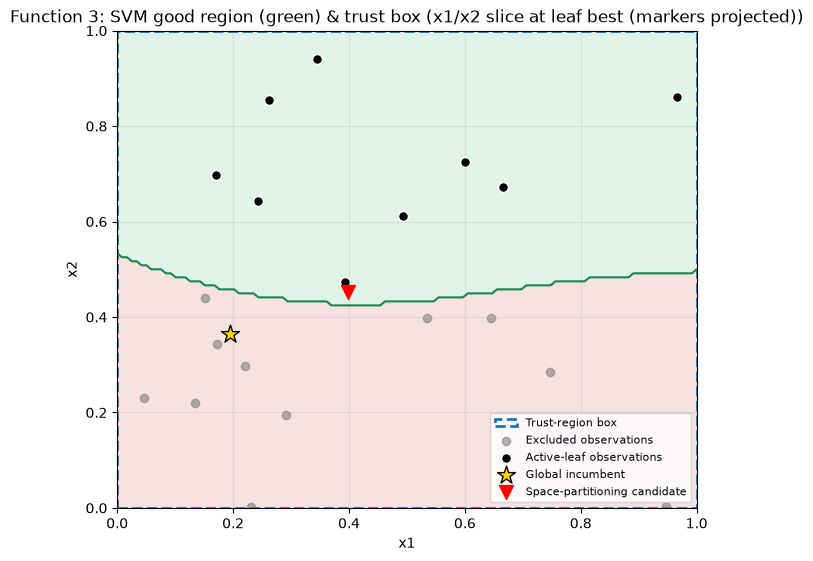

In [14]:
grid_n = 120
axis_grid = np.linspace(0.0, np.nextafter(1.0, 0.0), grid_n)
gx1, gx2 = np.meshgrid(axis_grid, axis_grid)
plane = np.tile(best_local_x, (gx1.size, 1))
plane[:, 0] = gx1.ravel()
plane[:, 1] = gx2.ravel()
good_plane = partition.predict_good(plane).reshape(gx1.shape)

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
ax.contourf(gx1, gx2, good_plane.astype(float), levels=[-0.5, 0.5, 1.5], colors=['#f2d7d5', '#d4efdf'], alpha=0.7)
if partition.splits:
    ax.contour(gx1, gx2, good_plane.astype(float), levels=[0.5], colors=['#1e8449'], linewidths=1.5)

rect = Rectangle(
    (sp_result.trust_lower[0], sp_result.trust_lower[1]),
    sp_result.trust_upper[0] - sp_result.trust_lower[0],
    sp_result.trust_upper[1] - sp_result.trust_lower[1],
    fill=False, edgecolor='tab:blue', linestyle='--', linewidth=2.0, label='Trust-region box',
)
ax.add_patch(rect)

excluded = observations.inputs[~active_mask]
included = observations.inputs[active_mask]
if len(excluded):
    ax.scatter(excluded[:, 0], excluded[:, 1], c='gray', alpha=0.6, s=35, label='Excluded observations')
ax.scatter(included[:, 0], included[:, 1], c='black', edgecolors='white', s=50, zorder=3, label='Active-leaf observations')
ax.scatter(observations.best_input[0], observations.best_input[1], c='gold', edgecolors='black', marker='*', s=180, zorder=4, label='Global incumbent')
ax.scatter(sp_result.candidate[0], sp_result.candidate[1], c='red', marker='v', s=100, zorder=5, label='Space-partitioning candidate')

slice_note = 'full 2D domain' if observations.dimension == 2 else 'x1/x2 slice at leaf best (markers projected)'
ax.set(
    title=f'Function {FUNCTION_ID}: SVM good region (green) & trust box ({slice_note})',
    xlabel='x1', ylabel='x2', xlim=(0, 1), ylim=(0, 1),
)
ax.legend(fontsize=8, loc='best')
ax.grid(alpha=0.25)
display(fig)
plt.close(fig)

## Step 5. Compare against the global `sobol_lbfgs` GP (in original output units)

Because the local GP may use rank-transformed targets, we score **both** candidates with the **same global reference GP** (using your Notebook 06 kernel and $\alpha$) so you can compare them directly in original objective units:

- Compare **distance to incumbent**, **global predicted mean ± std**, and **global EI**.
- Remember: a lower global GP prediction for the space-partitioning candidate does **not** automatically mean it is worse — on non-stationary functions (like F2 in Week 6), the global GP can over-smooth a local ridge that the local GP sees more clearly. Both numbers are model diagnostics, not measured outcomes.

,method,submission,dist_to_incumbent,dist_to_nearest_obs,global_gp_mean,global_gp_std,global_gp_ei
0,Space-partitioning (thompson),0.398370-0.451685-0.467286,0.221838,0.036723,-0.009017,0.010416,0.000778
1,"Global sobol_lbfgs (Rational Quadratic, a=0.1)",0.486601-0.768090-0.583814,0.512170,0.260297,-0.038991,0.066842,0.011035


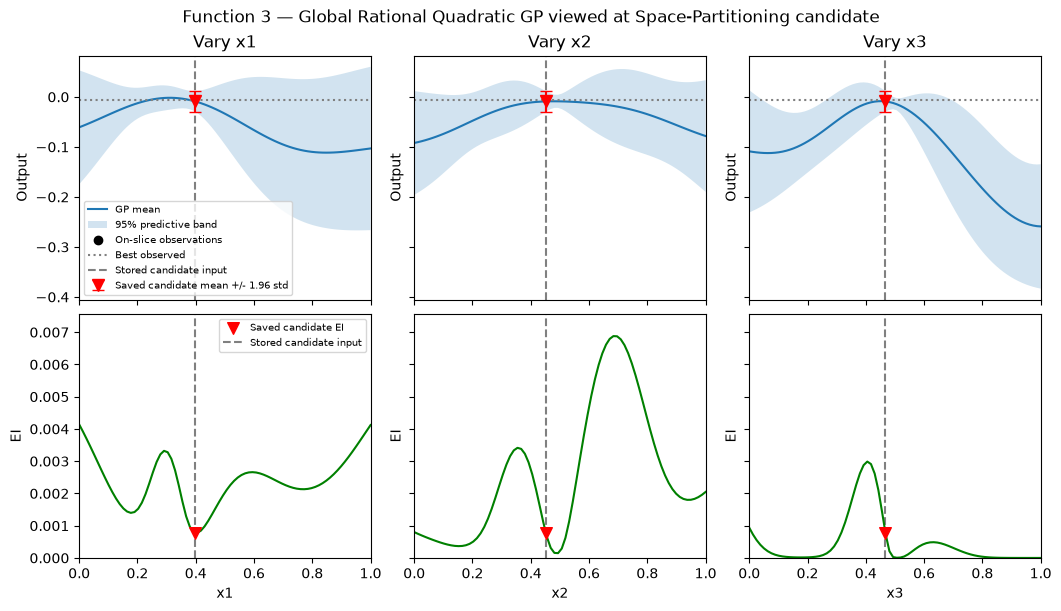

In [15]:
global_kernel_name = GLOBAL_KERNEL_MAP[FUNCTION_ID]
global_alpha = GLOBAL_ALPHA_MAP[FUNCTION_ID]
global_xi = float(global_alpha * np.std(observations.outputs))
global_kernel = make_comparison_kernels(
    observations.dimension, CONFIG['length_caps'][FUNCTION_ID],
)[global_kernel_name]

global_opt = BayesianOptimizer(
    observations,
    OptimisationConfig(
        budget=1,
        candidates=16_384,
        seed=CONFIG['random_state'],
        kernel=global_kernel,
        xi=global_xi,
        search_strategy='sobol_lbfgs',
    ),
)
g_pt, g_mean, g_std, g_ei = global_opt.suggest_with_prediction()
sp_g_mean, sp_g_std, sp_g_ei = [float(v[0]) for v in global_opt.predict(sp_result.candidate.reshape(1, -1))]

comparison = pd.DataFrame([
    {
        'method': f'Space-partitioning ({ACQUISITION})',
        'submission': format_submission(sp_result.candidate),
        'dist_to_incumbent': float(np.linalg.norm(sp_result.candidate - observations.best_input)),
        'dist_to_nearest_obs': float(np.min(np.linalg.norm(observations.inputs - sp_result.candidate, axis=1))),
        'global_gp_mean': sp_g_mean,
        'global_gp_std': sp_g_std,
        'global_gp_ei': sp_g_ei,
    },
    {
        'method': f'Global sobol_lbfgs ({global_kernel_name}, a={global_alpha:g})',
        'submission': format_submission(g_pt),
        'dist_to_incumbent': float(np.linalg.norm(g_pt - observations.best_input)),
        'dist_to_nearest_obs': float(np.min(np.linalg.norm(observations.inputs - g_pt, axis=1))),
        'global_gp_mean': g_mean,
        'global_gp_std': g_std,
        'global_gp_ei': g_ei,
    },
])
with pd.option_context('display.max_colwidth', None):
    display(comparison.round(6))

plot_fn = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
gp_fig, _ = plot_fn(
    global_opt, n=80,
    candidate=sp_result.candidate,
    expected_mean=sp_g_mean, expected_std=sp_g_std, expected_ei=sp_g_ei,
)
gp_fig.suptitle(
    f'Function {FUNCTION_ID} — Global {global_kernel_name} GP viewed at Space-Partitioning candidate'
)
display(gp_fig)
plt.close(gp_fig)

## How to interpret & experiment next

- **Try changing `FUNCTION_ID`** in Step 1 (`1`–`8`) to see how partitioning behaves across 2D–8D functions:
  - On **F1** (`n=16`), `USE_RANK_TRANSFORM=True` prevents the `-3.6e-3` outlier from swamping the tiny positive region.
  - On **F2** (`n=16`), the trust region stays centered on your rising Week 6 peak `(0.7126, 0.9266)` instead of jumping to the `[0.98, 0.01]` corner.
  - On **F4** (`n=36`), K-Means + SVM can isolate the higher-output basin from deep `-30` valleys.
- **Try toggling `ACQUISITION = 'ei'` vs. `'thompson'`:** Thompson sampling adds controlled stochastic exploration; `'ei'` is deterministic.
- **Try shrinking/widening `TRUST_LENGTH`** (`0.2` vs. `0.4` vs. `0.6`) to see the step-size trade-off directly in Step 3 and Step 4.